<ipython-input-4-8aa35d521656>:21: RuntimeWarning: divide by zero encountered in log
  result.append(np.log(abs(1 - 2*x)))


Text(0.5, 1.0, 'Map of x(t+1) = x(t) + r - x(t)^2 versus Lyapunov exponent')

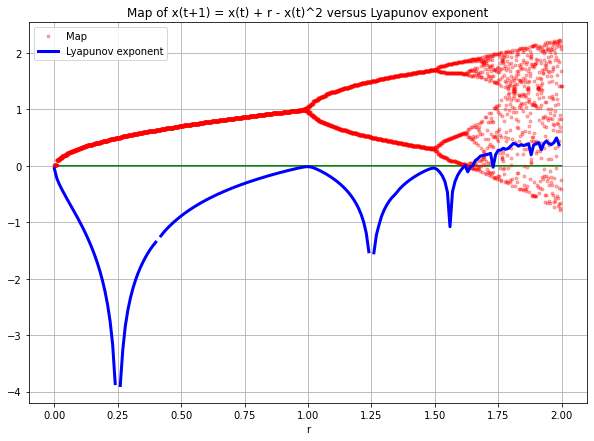

In [4]:
import numpy as np
import matplotlib.pyplot as plt
# show plots in notebook


result = []
lambdas = []
maps = []

# define range of r 
rvalues = np.arange(0, 2, 0.01)

# loop through r
for r in rvalues:
    x = 0.1
    result = []
    # iterate system 100 times
    for t in range(100):
        x = x + r - x**2
        # calculate log of the absolute of the derivative
        result.append(np.log(abs(1 - 2*x)))
    # take average
    lambdas.append(np.mean(result))
    # for the map ignore first 100 iterations as transient time and iterate anew
    for t in range(20):
        x = x + r - x**2
        maps.append(x)    
    
fig = plt.figure(figsize=(10,7))
ax1 = fig.add_subplot(1,1,1)

xticks = np.linspace(0, 2, 4000)
# zero line
zero = [0]*4000
ax1.plot(xticks, zero, 'g-')
# plot map
ax1.plot(xticks, maps, 'r.',alpha = 0.3, label = 'Map')
ax1.set_xlabel('r')
# plot lyapunov
ax1.plot(rvalues, lambdas, 'b-', linewidth = 3, label = 'Lyapunov exponent')
ax1.grid('on')
ax1.set_xlabel('r')
ax1.legend(loc='best')
ax1.set_title('Map of x(t+1) = x(t) + r - x(t)^2 versus Lyapunov exponent')

In [5]:
import numpy as np
import csv
import pandas as pd
from bokeh.plotting import figure, output_notebook, show
from bokeh.models import HoverTool
from bokeh.io import output_file
from bokeh.models import ColumnDataSource, NumeralTickFormatter
from bokeh.layouts import layout
from bokeh.layouts import column
from bokeh.models import RangeSlider
from bokeh.models.widgets import Slider, TextInput

from scipy.signal import find_peaks
import glob
import os

In [6]:
from bokeh.plotting import figure
from bokeh.embed import components
from bokeh.models import CustomJS, ColumnDataSource, Slider, LinearColorMapper, ColorBar, BasicTicker
from bokeh.palettes import Blues
from bokeh.palettes import Reds
from bokeh.palettes import inferno, viridis
from bokeh.models.widgets import DataTable, TableColumn
from bokeh.layouts import column, row
from bokeh.io import show
import itertools

colors1 = itertools.cycle(inferno(100))

colors_inf=[0]*100
for m in range(100):
    colors_inf[m]=next(colors1)

In [7]:
file_location = os.path.join(r'C:\Users\Austin\Documents\UMAP_projects\nsclc_model\umap_22_02_14', 'embedding_erl*.csv')
filenames = glob.glob(file_location)


In [8]:
import pandas as pd

lyap_erl = pd.read_csv('lyap_avg_0402.txt',header=None)
lyap_dmso = pd.read_csv('lyap_avg_dmso.txt',header=None)
lyap_sum = pd.read_csv('lyap_sum.txt',header=None)
x_lin = np.arange(0,1,0.01)

In [9]:
embedding_prot_ode_erl_7_7_1 = pd.read_csv('embedding_prot_ode_erl_7_7_1.csv',header=None)
embedding_prot_ode_erl_7_7_2 = pd.read_csv('embedding_prot_ode_erl_7_7_2.csv',header=None)
embedding_prot_ode_erl_7_7_3 = pd.read_csv('embedding_prot_ode_erl_7_7_3.csv',header=None)

In [10]:
from bokeh.transform import linear_cmap
import matplotlib as mpl
import matplotlib.cm


colors = [
    "#%02x%02x%02x" % (int(r), int(g), int(b)) for r, g, b, _ in 255*mpl.cm.inferno(mpl.colors.Normalize()(lyap_erl.iloc[0,:]))
]

In [11]:
# output to notebook
output_notebook()

# create figure
fig = figure(plot_width = 600, plot_height = 600, x_axis_label='UMAP 1',
             y_axis_label='UMAP 2', title='Stiffness range: FAK 0.4-1')
wid = 1

# output to notebook
output_notebook()

# create figure
fig = figure(plot_width = 600, plot_height = 600, x_axis_label='UMAP 1',
             y_axis_label='UMAP 2', title='Stiffness range: FAK 0.4-1')
wid = 1
ii=0
for f in filenames:
    embedding_tmp = pd.read_csv(f,header=None)
    
    fig.line(x=embedding_tmp.iloc[900:,0],
         y=embedding_tmp.iloc[900:,1],
         color=colors[ii], width = wid, alpha = 0.5)
    ii+=1
fig.legend.location = "top_left"



    
fig1 = figure(plot_width = 600, plot_height = 300, x_axis_label='Stiffness Param.',
             y_axis_label='Lyapunov Exp.')
fig1.xaxis.axis_label_text_font_size = "20pt"
fig1.xaxis.major_label_text_font_size = "15pt"
fig1.yaxis.axis_label_text_font_size = "20pt"
fig1.yaxis.major_label_text_font_size = "15pt"

fig1.circle(x_lin, lyap_erl.iloc[0,:], color=colors)
fig1.line(x_lin, lyap_erl.iloc[0,:], color='gray',width=0.3)



show(column(fig,fig1))

Loading BokehJS ...

Loading BokehJS ...

C:\Users\Austin\anaconda3\lib\site-packages\bokeh\models\plots.py:766: UserWarning: 
You are attempting to set `plot.legend.location` on a plot that has zero legends added, this will have no effect.

Before legend properties can be set, you must add a Legend explicitly, or call a glyph method with a legend parameter set.

  warnings.warn(_LEGEND_EMPTY_WARNING % attr)


In [12]:
from bokeh.models import Range1d
fig1 = figure(plot_width = 300, plot_height = 300, x_axis_label='Stiffness Param.',
             y_axis_label='Lyapunov Exp.')

fig1.y_range = Range1d(-0.12, 0)
fig1.xaxis.axis_label_text_font_size = "20pt"
fig1.xaxis.major_label_text_font_size = "15pt"
fig1.yaxis.axis_label_text_font_size = "20pt"
fig1.yaxis.major_label_text_font_size = "15pt"

fig1.circle(x_lin, lyap_erl.iloc[0,:], color=colors)
fig1.line(x_lin, lyap_erl.iloc[0,:], color='gray',width=0.3)



show(fig1)

In [13]:
colors = [
    "#%02x%02x%02x" % (int(r), int(g), int(b)) for r, g, b, _ in 255*mpl.cm.inferno(mpl.colors.Normalize()(lyap_dmso.iloc[0,:]))
]

In [20]:
fig1 = figure(plot_width = 600, plot_height = 300, x_axis_label='Stiffness Param.',
             y_axis_label='Lyapunov Exp.')
fig1.y_range = Range1d(-0.12, 0)
fig1.xaxis.axis_label_text_font_size = "20pt"
fig1.xaxis.major_label_text_font_size = "15pt"
fig1.yaxis.axis_label_text_font_size = "20pt"
fig1.yaxis.major_label_text_font_size = "15pt"

fig1.circle(x_lin, lyap_dmso.iloc[0,:], color=colors)
fig1.line(x_lin, lyap_dmso.iloc[0,:], color='gray',width=0.3)



show(fig1)

In [15]:
from mpl_toolkits import mplot3d
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

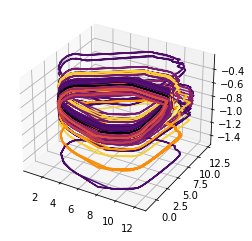

In [16]:
fig = plt.figure()
ax = plt.axes(projection='3d')

ii=0
for f in filenames:
    embedding_tmp = pd.read_csv(f,header=None)
    ax.plot3D(embedding_tmp.iloc[900:,0], embedding_tmp.iloc[900:,1], [lyap_sum.iloc[0,ii]]*95, colors[ii])
    
    ii+=1

In [17]:
tmp=embedding_tmp.iloc[900:,0]
tmp

900    10.701708
901    10.681579
902    10.633900
903    10.497020
904    10.198106
         ...    
990     8.677898
991     7.275723
992     5.974384
993     3.186608
994     2.057195
Name: 0, Length: 95, dtype: float64